# [3.9] Preprocessing/CV Throughput - Batch Benchmark

**Sprint demo:** Measure representative image batches, identify expensive stages,
and verify that a performance change preserves measurements and scoring outcomes.

**Interface:** fixed photographs -> loading -> preprocessing -> configured CV -> scoring.

This notebook uses the project's real preprocessing and scoring pipeline.
The default scope covers brightness, contrast, and color palette analysis.
Standardization uses the batch worker's 2048 x 2048 bounding box.

**Scope:** VLM requests, subject detection, framing/sharpness analysis, persistent
PNG saving, and database operations are outside this benchmark. Results describe
the measured preprocessing/CV workload, rather than full API-job throughput.

A baseline run records current behavior. Performance acceptance is assessed only
after an optimized run is compared with that saved baseline.


## 1. Imports and repository setup

Select the project's `.venv` notebook kernel. The repository root is detected
whether this notebook is launched from the root directory or `examples/`.


In [20]:
import hashlib
import io
import json
import logging
import math
import platform
import re
import subprocess
from dataclasses import asdict
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from brandlens.config import load_cv_config
from brandlens.logger import image_logging_context, track_current_stage
from brandlens.pipeline import score_standardized_image
from brandlens.preprocessing.image_io import load_image
from brandlens.preprocessing.photo_filter import FilterSettings, filter_reject_reason
from brandlens.preprocessing.preprocessor import preprocess_image
from brandlens.preprocessing.standardization import StandardizationSettings

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "src" / "brandlens").is_dir()
    and (p / "config" / "brand_standards.json").is_file()
)


def git_output(*args):
    return subprocess.check_output(
        ["git", *args], cwd=ROOT, text=True
    ).strip()


print("Repository:", ROOT)


Repository: f:\V_Tech Semesters\MS Thesis\Jupyter_MS\git\visual-brand-audit


## 2. Configure the benchmark once

Keep the photographs, rubric, settings, dependencies, and machine consistent
between baseline and optimized runs.

- One complete warm-up batch is excluded from the measurements.
- Three measured runs use the same ten photographs in the same order.
- Configuration loading is outside the timed region.
- Both runs use the same stage logging.
- Exact equality is required for standardized pixel hashes and discrete outcomes.
- Numeric outputs use the tolerances below, declared before optimization.

For the first run, leave `RUN_LABEL = "baseline"` and `BASELINE_JSON = None`.
After optimization, change the label to `"optimized"` and point `BASELINE_JSON`
to the saved baseline's `run.json`. Restart the kernel and run all cells.


In [21]:
# RUN_LABEL = "baseline" # Change this to "baseline" or "optimized" to select the run type.
# BASELINE_JSON = None  

RUN_LABEL = "optimized" # Change this to "baseline" or "optimized" to select the run type.
BASELINE_JSON = rf'{ROOT}\benchmarks\3_9\baseline_20261116T214849195871Z\run.json'
# Optional third row: load a previous run.json without processing it again.
OLD_RUN_JSON = None
# OLD_RUN_JSON = "benchmarks/3_9/optimized_20261116T234404698970Z/run.json"

REPEATS = 3
RTOL = 1e-9
ATOL = 1e-9
SHOW_PREVIEW = True
TEAM_TARGET_IPS = None  # Set only if the team has documented a target.

if RUN_LABEL not in {"baseline", "optimized"}:
    raise ValueError("RUN_LABEL must be 'baseline' or 'optimized'.")
if REPEATS < 3:
    raise ValueError("Use at least three measured repetitions.")
if TEAM_TARGET_IPS is not None and TEAM_TARGET_IPS <= 0:
    raise ValueError("The team target must be positive.")

CONFIG_PATH = ROOT / "config" / "brand_standards.json"
configuration = load_cv_config(CONFIG_PATH)

CRITERION_IDS = [
    "exposure_brightness",
    "contrast",
    "color_palette_fit",
]
FILTER = FilterSettings()
STANDARDIZATION = StandardizationSettings(max_size=(2048, 2048))

print("Run label:", RUN_LABEL)
print("Selected criteria:", ", ".join(CRITERION_IDS))
print("Standardization:", asdict(STANDARDIZATION))
print(f"Numeric comparison: rtol={RTOL}, atol={ATOL}")


Run label: optimized
Selected criteria: exposure_brightness, contrast, color_palette_fit
Standardization: {'max_size': (2048, 2048), 'background': (255, 255, 255)}
Numeric comparison: rtol=1e-09, atol=1e-09


## 3. Inspect and freeze the representative batch

The default batch contains ten photography examples already in
`brand-portal-images/all/`. Inspect the previews before treating this selection
as representative of the team's expected photographs.

The input manifest records dimensions, file sizes, and content hashes.
Standardized pixel hashes are captured outside the timed runs.
Unexpected exclusions stop the benchmark instead of silently reducing its workload.


,file,width,height,file_bytes
0,il-std-ph-Do1new.png,912,682,251252
1,il-std-ph-Do2new.png,912,682,475009
2,il-std-ph-Do3new.png,912,682,831077
3,il-std-ph-Dont1new.png,912,682,241727
4,il-std-ph-Dont2new.png,912,682,428600
5,il-std-ph-Dont3new.png,912,682,536247
6,il-std-ph-EditingDo1.png,914,676,999996
7,il-std-ph-EditingDont1-new.png,915,680,980476
8,il-std-ph-EditingDo2-new.png,913,682,1328948
9,il-std-ph-EditingDont2.png,912,682,1268245


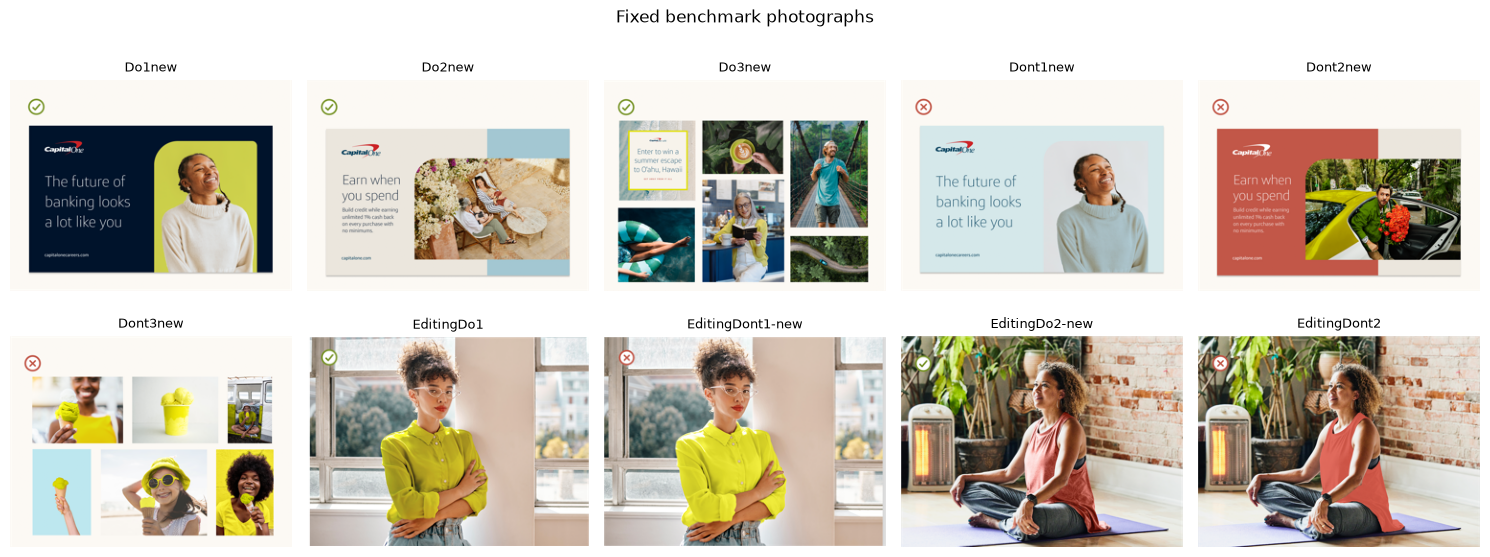

In [22]:
PHOTO_DIR = ROOT / "brand-portal-images" / "all"
FILENAMES = [
    f"il-std-ph-{kind}{number}new.png"
    for kind in ("Do", "Dont")
    for number in (1, 2, 3)
] + [
    "il-std-ph-EditingDo1.png",
    "il-std-ph-EditingDont1-new.png",
    "il-std-ph-EditingDo2-new.png",
    "il-std-ph-EditingDont2.png",
]
PATHS = [PHOTO_DIR / name for name in FILENAMES]

missing = [p.name for p in PATHS if not p.is_file()]
if missing:
    raise FileNotFoundError(f"Missing benchmark photographs: {missing}")

manifest = []
pixel_reference = {}

for path in PATHS:
    with load_image(path) as image:
        reason = filter_reject_reason(image, FILTER)
        if reason:
            raise ValueError(f"{path.name}: rejected because {reason}")

        manifest.append({
            "file": path.name,
            "width": image.width,
            "height": image.height,
            "file_bytes": path.stat().st_size,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        })

        standardized = preprocess_image(image, FILTER, STANDARDIZATION)
        if standardized is None:
            raise RuntimeError(f"Unexpected exclusion: {path.name}")

        with standardized:
            pixel_reference[path.name] = {
                "size": list(standardized.size),
                "mode": standardized.mode,
                "rgb_sha256": hashlib.sha256(
                    standardized.tobytes()
                ).hexdigest(),
            }

display(pd.DataFrame(manifest).drop(columns="sha256"))

if SHOW_PREVIEW:
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for axis, path in zip(axes.flat, PATHS, strict=True):
        with load_image(path) as image:
            with image.copy() as preview:
                preview.thumbnail((320, 220))
                axis.imshow(preview)
        axis.set_title(path.stem.replace("il-std-ph-", ""), fontsize=9)
        axis.axis("off")
    fig.suptitle("Fixed benchmark photographs")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


## 4. Define the batch runner and output comparison

Each image is loaded and preprocessed once per run, then passed to
`score_standardized_image()` with the selected criteria.

All three selected CV measurements must be available. A failed or skipped
measurement stops the run, so skipping work cannot appear as an improvement.

The comparison checks complete CV/scoring output structures. Strings, flags,
missing values, and other discrete values must match exactly; numeric values
use the declared tolerance.


In [23]:
def run_batch(run_id):
    outputs = {}
    start = perf_counter()

    for index, path in enumerate(PATHS):
        with image_logging_context(run_id, f"image-{index:03d}"):
            with track_current_stage("image_loading"):
                raw = load_image(path)

            with raw:
                standardized = preprocess_image(raw, FILTER, STANDARDIZATION)
                if standardized is None:
                    raise RuntimeError(f"Unexpected exclusion: {path.name}")

                with standardized:
                    scored, cv_results, _ = score_standardized_image(
                        standardized,
                        configuration,
                        criterion_ids=CRITERION_IDS,
                    )

            unavailable = [
                cid for cid in CRITERION_IDS
                if cv_results[cid]["status"] != "available"
            ]
            if unavailable:
                raise RuntimeError(
                    f"{path.name}: unavailable measurements: {unavailable}"
                )

            outputs[path.name] = {
                "score": asdict(scored),
                "cv": cv_results,
            }

    elapsed = perf_counter() - start
    return elapsed, outputs


def equivalent(a, b):
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(
            equivalent(a[key], b[key]) for key in a
        )
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(
            equivalent(x, y) for x, y in zip(a, b, strict=True)
        )
    if isinstance(a, bool) or isinstance(b, bool):
        return type(a) is type(b) and a == b
    if isinstance(a, (int, float)) and isinstance(b, (int, float)):
        return math.isclose(a, b, rel_tol=RTOL, abs_tol=ATOL)
    return type(a) is type(b) and a == b


## 5. Run the warm-up and measured batches

These are steady-state measurements after warm-up. They do not represent a
cold start, model initialization, or uncached storage performance.

The logging handler is detached and the original logger settings restored
even if a batch raises an exception.


In [24]:
pipeline_logger = logging.getLogger("brandlens.pipeline")
previous_level = pipeline_logger.level
previous_propagate = pipeline_logger.propagate

stream = io.StringIO()
handler = logging.StreamHandler(stream)
handler.setFormatter(logging.Formatter("%(message)s"))

runs = []
run_outputs = []

pipeline_logger.setLevel(logging.INFO)
pipeline_logger.propagate = False
pipeline_logger.addHandler(handler)

try:
    print("Running one warm-up batch...")
    run_batch("warmup")
    stream.seek(0)
    stream.truncate(0)

    for repeat in range(1, REPEATS + 1):
        elapsed, outputs = run_batch(f"{RUN_LABEL}-{repeat}")
        runs.append({
            "repeat": repeat,
            "images": len(PATHS),
            "batch_seconds": elapsed,
            "images_per_second": len(PATHS) / elapsed,
        })
        run_outputs.append(outputs)
        print(f"Run {repeat}: {elapsed:.3f} seconds")

finally:
    pipeline_logger.removeHandler(handler)
    pipeline_logger.setLevel(previous_level)
    pipeline_logger.propagate = previous_propagate
    handler.close()

LOG_TEXT = stream.getvalue()
repeat_consistent = all(
    equivalent(run_outputs[0], output) for output in run_outputs[1:]
)
print("Repeated outputs consistent:", repeat_consistent)


Running one warm-up batch...
Run 1: 2.268 seconds
Run 2: 2.107 seconds
Run 3: 2.182 seconds
Repeated outputs consistent: True


## 6. Inspect throughput and stage timings

Batch throughput uses the complete timed batch, including the processing loop
and output collection. Stage timings come from the existing instrumentation.

Stage durations are rounded by the logger and do not cover every part of the
batch. Their sum is not a substitute for the measured batch wall time.


Individual repetitions:


,repeat,images,batch_seconds,images_per_second
0,1,10,2.268329,4.408532
1,2,10,2.107301,4.745406
2,3,10,2.181725,4.583530


Batch summary:


,run_label,images_per_batch,measured_runs,median_batch_seconds,median_images_per_second,seconds_per_image_at_median,minimum_batch_seconds,maximum_batch_seconds,repeat_outputs_consistent
0,optimized,10,3,2.181725,4.58353,0.218172,2.107301,2.268329,True


Measured stage costs:


,stage,calls,total_ms,mean_per_call_ms,mean_per_batch_ms
0,cv:color_palette_fit,30,5426.9,180.896667,1808.966667
4,image_loading,30,393.7,13.123333,131.233333
1,cv:contrast,30,337.3,11.243333,112.433333
6,standardization,30,230.4,7.680000,76.800000
2,cv:exposure_brightness,30,135.6,4.520000,45.200000
3,cv_input,30,0.8,0.026667,0.266667
5,photo_filter,30,0.0,0.000000,0.000000


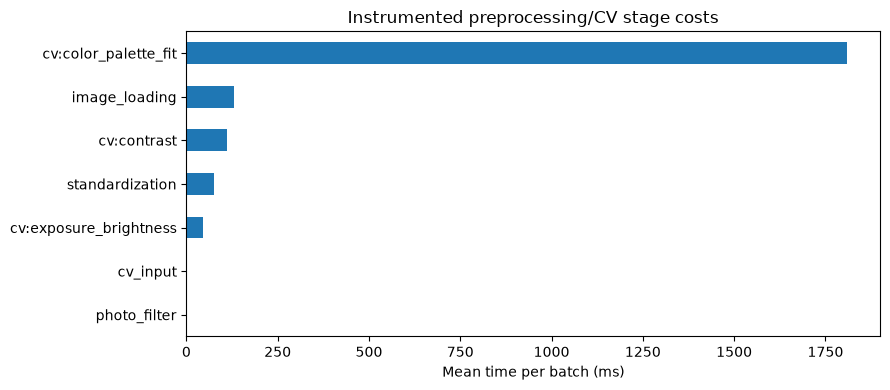

In [25]:
runs_df = pd.DataFrame(runs)
median_seconds = float(runs_df["batch_seconds"].median())
median_ips = len(PATHS) / median_seconds

summary = pd.DataFrame([{
    "run_label": RUN_LABEL,
    "images_per_batch": len(PATHS),
    "measured_runs": REPEATS,
    "median_batch_seconds": median_seconds,
    "median_images_per_second": median_ips,
    "seconds_per_image_at_median": median_seconds / len(PATHS),
    "minimum_batch_seconds": runs_df["batch_seconds"].min(),
    "maximum_batch_seconds": runs_df["batch_seconds"].max(),
    "repeat_outputs_consistent": repeat_consistent,
}])

print("Individual repetitions:")
display(runs_df)
print("Batch summary:")
display(summary)

matches = re.findall(
    r"\bstage=(\S+) status=completed duration_ms=([0-9.]+)",
    LOG_TEXT,
)
if not matches:
    raise RuntimeError("No stage timings captured. Check the logging setup.")

stage_df = pd.DataFrame(matches, columns=["stage", "duration_ms"])
stage_df["duration_ms"] = stage_df["duration_ms"].astype(float)

stage_summary = (
    stage_df.groupby("stage")["duration_ms"]
    .agg(calls="count", total_ms="sum", mean_per_call_ms="mean")
    .reset_index()
)
stage_summary["mean_per_batch_ms"] = stage_summary["total_ms"] / REPEATS
stage_summary = stage_summary.sort_values(
    "mean_per_batch_ms", ascending=False
)

print("Measured stage costs:")
display(stage_summary)

fig, axis = plt.subplots(figsize=(9, 4))
stage_summary.sort_values("mean_per_batch_ms").plot.barh(
    x="stage", y="mean_per_batch_ms", legend=False, ax=axis
)
axis.set_xlabel("Mean time per batch (ms)")
axis.set_ylabel("")
axis.set_title("Instrumented preprocessing/CV stage costs")
plt.tight_layout()
plt.show()
plt.close(fig)


## 7. Save reproducible evidence

Each execution creates a new timestamped directory under `benchmarks/3_9/`.
Existing baseline evidence is preserved.

The saved JSON contains the input manifest, settings, resolved rubric,
environment information, raw measurements/scores from every repetition,
and standardized pixel hashes. CSV files and stage logs support the demo.


In [26]:
controls = {
    "scope": "loading + preprocessing + brightness/contrast/color + scoring",
    "manifest": manifest,
    "criteria": CRITERION_IDS,
    "filter_settings": asdict(FILTER),
    "standardization_settings": asdict(STANDARDIZATION),
    "configuration": configuration[0],
    "numeric_tolerance": {"rtol": RTOL, "atol": ATOL},
}
environment = {
    "platform": platform.platform(),
    "processor": platform.processor(),
    "python": platform.python_version(),
    "versions": {
        name: version(name)
        for name in ("numpy", "Pillow", "scikit-learn", "opencv-python")
    },
}
stamp = datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
OUT_DIR = ROOT / "benchmarks" / "3_9" / f"{RUN_LABEL}_{stamp}"
OUT_DIR.mkdir(parents=True, exist_ok=False)

evidence = {
    "run_label": RUN_LABEL,
    "created_utc": stamp,
    "branch": git_output("branch", "--show-current"),
    "commit": git_output("rev-parse", "HEAD"),
    "tracked_changes": git_output(
        "status", "--porcelain", "--untracked-files=no"
    ),
    "controls": controls,
    "environment": environment,
    "runs": runs,
    "summary": summary.to_dict(orient="records")[0],
    "outputs_by_run": run_outputs,
    "standardized_pixels": pixel_reference,
}

RUN_JSON = OUT_DIR / "run.json"
RUN_JSON.write_text(
    json.dumps(evidence, indent=2, allow_nan=False), encoding="utf-8"
)
(OUT_DIR / "stage_timings.log").write_text(LOG_TEXT, encoding="utf-8")
runs_df.to_csv(OUT_DIR / "runs.csv", index=False)
summary.to_csv(OUT_DIR / "summary.csv", index=False)
stage_summary.to_csv(OUT_DIR / "stages.csv", index=False)

print("Saved evidence:", OUT_DIR)
print("JSON for the later comparison:", RUN_JSON)
assert repeat_consistent, (
    "Evidence was saved, but repeated outputs differ beyond tolerance. "
    "Investigate repeatability before making performance claims."
)


Saved evidence: f:\V_Tech Semesters\MS Thesis\Jupyter_MS\git\visual-brand-audit\benchmarks\3_9\optimized_20261116T234404698970Z
JSON for the later comparison: f:\V_Tech Semesters\MS Thesis\Jupyter_MS\git\visual-brand-audit\benchmarks\3_9\optimized_20261116T234404698970Z\run.json


## 8. Compare with the saved baseline

For an optimized run, set `BASELINE_JSON` in section 2 to the original baseline's
`run.json`, then restart the kernel and run all cells.

Comparison requires matching inputs, configuration, environment, standardized
pixels, and outputs within the declared tolerance. Throughput acceptance requires
an improved measured median or a documented team target being met.

Inspect the individual run ranges as well as the median. A small difference
within normal timing variation needs further measurement.

Optionally set `OLD_RUN_JSON` in section 2 to another saved `run.json`.
It appears as a third row named `old_run` in the same comparison table, with
speedup relative to the baseline. The notebook prints the loaded run path.
Old-run compatibility checks are shown separately; incompatible historical runs
have no speedup value and do not change the current run's acceptance checks.


In [ ]:
if BASELINE_JSON is None:
    print("Baseline recorded. Performance improvement has not yet been assessed.")
else:
    baseline_path = Path(BASELINE_JSON)
    if not baseline_path.is_absolute():
        baseline_path = ROOT / baseline_path

    baseline = json.loads(baseline_path.read_text(encoding="utf-8"))
    old_seconds = baseline["summary"]["median_batch_seconds"]
    old_ips = baseline["summary"]["median_images_per_second"]

    current_controls = json.loads(json.dumps(controls))
    same_controls = baseline["controls"] == current_controls
    same_environment = baseline["environment"] == environment
    same_pixels = baseline["standardized_pixels"] == pixel_reference
    same_outputs = all(
        equivalent(baseline["outputs_by_run"][0], output)
        for output in run_outputs
    )
    baseline_repeatable = baseline["summary"]["repeat_outputs_consistent"]
    improved = median_ips > old_ips
    target_met = TEAM_TARGET_IPS is not None and median_ips >= TEAM_TARGET_IPS

    comparison = pd.DataFrame([
        {
            "version": "baseline",
            "median_batch_seconds": old_seconds,
            "images_per_second": old_ips,
            "speedup": 1.0,
        },
        {
            "version": RUN_LABEL,
            "median_batch_seconds": median_seconds,
            "images_per_second": median_ips,
            "speedup": old_seconds / median_seconds,
        },
    ])
    old_run_checks = None
    if OLD_RUN_JSON is not None:
        old_run_path = Path(OLD_RUN_JSON)
        if not old_run_path.is_absolute():
            old_run_path = ROOT / old_run_path
        old_run = json.loads(old_run_path.read_text(encoding="utf-8"))
        old_run_checks = pd.DataFrame([
            ("Old run is repeatable", old_run["summary"]["repeat_outputs_consistent"]),
            ("Old run inputs and settings match", old_run["controls"] == current_controls),
            ("Old run environment matches", old_run["environment"] == environment),
            ("Old run standardized pixels match", old_run["standardized_pixels"] == pixel_reference),
            ("Old run CV/scoring outputs match", all(
                equivalent(old_run["outputs_by_run"][0], output)
                for output in run_outputs
            )),
        ], columns=["check", "passed"])
        old_run_comparable = bool(old_run_checks["passed"].all())
        comparison.loc[len(comparison)] = {
            "version": "old_run",
            "median_batch_seconds": old_run["summary"]["median_batch_seconds"],
            "images_per_second": old_run["summary"]["median_images_per_second"],
            "speedup": (
                old_seconds / old_run["summary"]["median_batch_seconds"]
                if old_run_comparable else float("nan")
            ),
        }
        print("Old run results loaded from:", old_run_path)
        if not old_run_comparable:
            print("Old run compatibility checks failed; its speedup is unavailable.")

    checks = pd.DataFrame([
        ("Baseline is repeatable", baseline_repeatable),
        ("Current run is repeatable", repeat_consistent),
        ("Inputs and settings match", same_controls),
        ("Environment matches", same_environment),
        ("Standardized pixels match exactly", same_pixels),
        ("CV/scoring outputs match within tolerance", same_outputs),
        ("Median throughput improves or team target is met", improved or target_met),
    ], columns=["check", "passed"])

    display(comparison)
    display(checks)
    if old_run_checks is not None:
        display(old_run_checks)
        old_run_checks.to_csv(OUT_DIR / "old_run_checks.csv", index=False)
    comparison.to_csv(OUT_DIR / "comparison.csv", index=False)
    checks.to_csv(OUT_DIR / "comparison_checks.csv", index=False)

    assert checks["passed"].all(), (
        "One or more comparison checks failed. Inspect the saved evidence "
        "before claiming acceptance."
    )
    print("All baseline/current acceptance checks passed for this benchmark scope.")
